# Commodity Price Forecasting — Regime Detection & Backtest
### Project by Rayan Rawat

This notebook covers:
- Market regime classification (Bull/Bear/Choppy)
- XGBoost signal generation
- Vectorised backtest with transaction costs
- Performance metrics: Sharpe ratio, max drawdown, win rate
- Comparison against buy and hold benchmark

In [1]:
# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
from xgboost import XGBRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1 — Load Data and Recreate XGBoost Model
We reload BRENT data and retrain XGBoost to generate
price direction signals for our trading strategy.

In [2]:
# Load BRENT data
df = pd.read_csv('data/BRENT.csv',
                  index_col='Date',
                  parse_dates=True)

column_mapping = {'C':'Close','H':'High','L':'Low','O':'Open','V':'Volume'}
df.rename(columns=column_mapping, inplace=True)

brent = df[['Close']].copy()
brent['Log_Return'] = np.log(brent['Close'] / brent['Close'].shift(1))

print(f"Loaded BRENT: {brent.shape[0]} rows")
print(f"Date range  : {brent.index[0].date()} to {brent.index[-1].date()}")

Loaded BRENT: 4192 rows
Date range  : 2010-01-04 to 2026-10-16


## Step 2 — Feature Engineering and XGBoost Signal
We recreate features from Notebook 3 and retrain XGBoost.
Then generate daily price direction signals: +1 (up) or -1 (down).

In [3]:
# STEP 2 — Feature engineering

def create_features(df):
    df = df.copy()
    df['lag_1']  = df['Close'].shift(1)
    df['lag_5']  = df['Close'].shift(5)
    df['lag_21'] = df['Close'].shift(21)
    df['lag_63'] = df['Close'].shift(63)
    df['rolling_mean_5']  = df['Close'].shift(1).rolling(5).mean()
    df['rolling_mean_21'] = df['Close'].shift(1).rolling(21).mean()
    df['rolling_mean_63'] = df['Close'].shift(1).rolling(63).mean()
    df['rolling_std_21']  = df['Close'].shift(1).rolling(21).std()
    df['rolling_std_63']  = df['Close'].shift(1).rolling(63).std()
    df['return_1d']  = df['Log_Return'].shift(1)
    df['return_5d']  = df['Log_Return'].shift(1).rolling(5).sum()
    df['return_21d'] = df['Log_Return'].shift(1).rolling(21).sum()
    df['month']       = df.index.month
    df['quarter']     = df.index.quarter
    df['day_of_week'] = df.index.dayofweek
    df['week_of_year']= df.index.isocalendar().week.astype(int)
    df['price_to_ma21'] = df['Close'] / df['rolling_mean_21']
    df['price_to_ma63'] = df['Close'] / df['rolling_mean_63']
    df['vol_ratio'] = df['rolling_std_21'] / df['rolling_std_63']
    return df.dropna()

brent_features = create_features(brent)

feature_cols = [
    'lag_1','lag_5','lag_21','lag_63',
    'rolling_mean_5','rolling_mean_21','rolling_mean_63',
    'rolling_std_21','rolling_std_63',
    'return_1d','return_5d','return_21d',
    'month','quarter','day_of_week','week_of_year',
    'price_to_ma21','price_to_ma63','vol_ratio'
]

# Train/test split
train_xgb = brent_features[brent_features.index < '2023-01-01']
test_xgb  = brent_features[brent_features.index >= '2023-01-01']

X_train = train_xgb[feature_cols]
y_train = train_xgb['Close']
X_test  = test_xgb[feature_cols]
y_test  = test_xgb['Close']

# Retrain XGBoost
xgb_model = XGBRegressor(
    n_estimators=1000, learning_rate=0.01,
    max_depth=4, subsample=0.8,
    colsample_bytree=0.8, random_state=42,
    early_stopping_rounds=50
)

xgb_model.fit(X_train, y_train,
              eval_set=[(X_test, y_test)],
              verbose=False)

# Generate predictions
xgb_predictions = xgb_model.predict(X_test)

# Generate direction signal
# +1 = predict price goes UP tomorrow
# -1 = predict price goes DOWN tomorrow
test_xgb = test_xgb.copy()
test_xgb['XGB_Predicted'] = xgb_predictions
test_xgb['XGB_Signal'] = np.where(
    test_xgb['XGB_Predicted'] > test_xgb['lag_1'], 1, -1
)

print(f"Signals generated: {len(test_xgb)} days")
print(f"Buy signals  (+1): {(test_xgb['XGB_Signal']==1).sum()}")
print(f"Sell signals (-1): {(test_xgb['XGB_Signal']==-1).sum()}")

Signals generated: 954 days
Buy signals  (+1): 500
Sell signals (-1): 454


## Step 3 — Market Regime Detection
We classify each day as Bull, Bear or Choppy regime
using 63-day rolling z-score of returns.
This filters out low-conviction trading days.

Regime distribution (2010-2026):
Regime_Label
Bull      1723
Bear      1589
Choppy     880
Name: count, dtype: int64

Bull  %: 41.1%
Bear  %: 37.9%
Choppy%: 21.0%


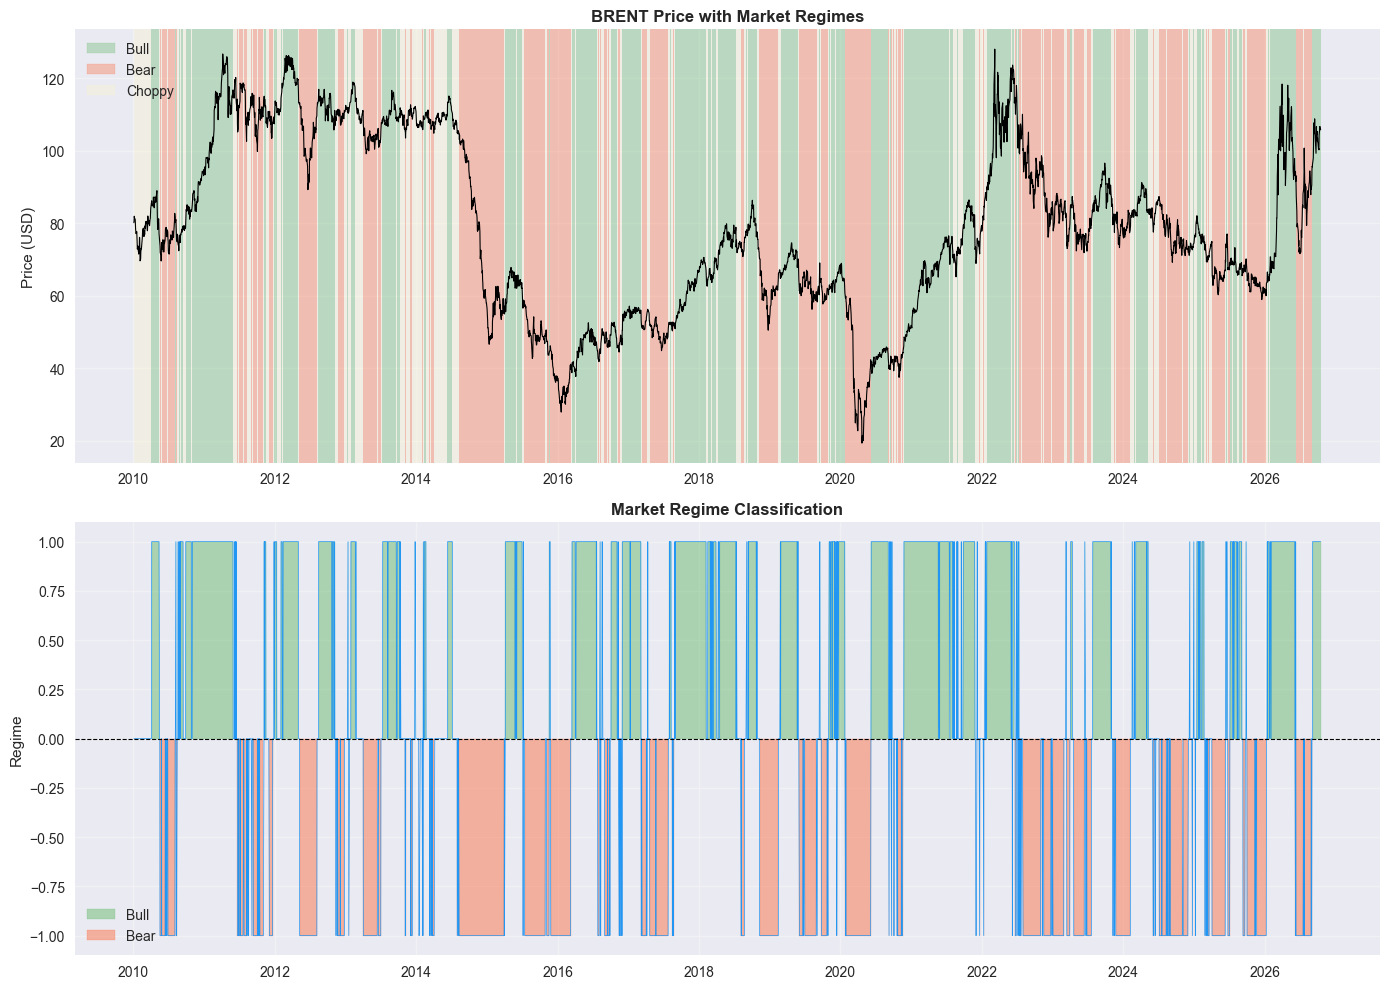

Chart saved!


In [4]:
# STEP 3 — REGIME DETECTION

# Calculate rolling 63-day mean and std of returns
rolling_mean = brent['Log_Return'].rolling(63).mean()
rolling_std  = brent['Log_Return'].rolling(63).std()

# Z-score = how many std devs is current return from rolling mean
brent['Z_Score'] = (brent['Log_Return'] - rolling_mean) / rolling_std

# Classify regime based on rolling mean return
rolling_return = brent['Log_Return'].rolling(63).mean()

brent['Regime'] = np.where(rolling_return >  0.0005,  1,   # Bull
                  np.where(rolling_return < -0.0005, -1,   # Bear
                                                      0))  # Choppy

# Map numbers to labels for readability
regime_map = {1: 'Bull', -1: 'Bear', 0: 'Choppy'}
brent['Regime_Label'] = brent['Regime'].map(regime_map)

# Count regimes over full history
print("Regime distribution (2010-2026):")
print(brent['Regime_Label'].value_counts())
print(f"\nBull  %: {(brent['Regime']==1).mean()*100:.1f}%")
print(f"Bear  %: {(brent['Regime']==-1).mean()*100:.1f}%")
print(f"Choppy%: {(brent['Regime']==0).mean()*100:.1f}%")

# ── Plot regimes ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Top — price with regime background
ax1 = axes[0]
ax1.plot(brent.index, brent['Close'],
         color='black', linewidth=0.8, label='BRENT Price')

# Shade background by regime
for i in range(1, len(brent)):
    regime = brent['Regime'].iloc[i]
    color  = '#4CAF50' if regime == 1 else '#FF5722' if regime == -1 else '#FFF9C4'
    ax1.axvspan(brent.index[i-1], brent.index[i],
                alpha=0.3, color=color, linewidth=0)

# Legend patches
bull_patch   = mpatches.Patch(color='#4CAF50', alpha=0.3, label='Bull')
bear_patch   = mpatches.Patch(color='#FF5722', alpha=0.3, label='Bear')
choppy_patch = mpatches.Patch(color='#FFF9C4', alpha=0.3, label='Choppy')
ax1.legend(handles=[bull_patch, bear_patch, choppy_patch])
ax1.set_title('BRENT Price with Market Regimes', fontweight='bold')
ax1.set_ylabel('Price (USD)')
ax1.grid(True, alpha=0.3)

# Bottom — regime over time as line
ax2 = axes[1]
ax2.plot(brent.index, brent['Regime'],
         color='#2196F3', linewidth=0.5)
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.fill_between(brent.index, brent['Regime'], 0,
                 where=brent['Regime'] > 0,
                 color='#4CAF50', alpha=0.4, label='Bull')
ax2.fill_between(brent.index, brent['Regime'], 0,
                 where=brent['Regime'] < 0,
                 color='#FF5722', alpha=0.4, label='Bear')
ax2.set_title('Market Regime Classification', fontweight='bold')
ax2.set_ylabel('Regime')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/regime_detection.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved!")

## Step 4 — Combine Regime + XGBoost Signal
Final trading signal combines regime filter with XGBoost direction:
- Bull regime + XGBoost says UP   → BUY (+1)
- Bear regime + XGBoost says DOWN → SELL (-1)
- Choppy regime                   → FLAT (0) — no trade

In [5]:
# STEP 4 — BETTER SIGNAL GENERATION

test_xgb = test_xgb.copy()

# Calculate predicted return properly
# How much does XGBoost predict price will change?
test_xgb['Predicted_Return'] = (
    test_xgb['XGB_Predicted'] - test_xgb['lag_1']) / test_xgb['lag_1']

# Only take strong signals — filter out weak predictions
# This avoids trading on noise
SIGNAL_THRESHOLD = 0.002  # only trade if predicted move > 0.2%

test_xgb['XGB_Signal'] = np.where(
    test_xgb['Predicted_Return'] >  SIGNAL_THRESHOLD,  1,
    np.where(
    test_xgb['Predicted_Return'] < -SIGNAL_THRESHOLD, -1,
    0))

# Add regime filter
test_xgb['Regime'] = brent['Regime'].reindex(test_xgb.index)

# Combined signal
test_xgb['Final_Signal'] = np.where(
    (test_xgb['Regime'] == 1)  & (test_xgb['XGB_Signal'] == 1),   1,
    np.where(
    (test_xgb['Regime'] == -1) & (test_xgb['XGB_Signal'] == -1),  -1,
    0))

print("Final signal distribution:")
print(f"  Buy  (+1): {(test_xgb['Final_Signal']==1).sum()} days")
print(f"  Sell (-1): {(test_xgb['Final_Signal']==-1).sum()} days")
print(f"  Flat ( 0): {(test_xgb['Final_Signal']==0).sum()} days")
print(f"\nActive trading days: {(test_xgb['Final_Signal']!=0).sum()} / {len(test_xgb)}")

Final signal distribution:
  Buy  (+1): 165 days
  Sell (-1): 228 days
  Flat ( 0): 561 days

Active trading days: 393 / 954


## Step 5 — Vectorised Backtest
We simulate trading from 2023-2026 using our final signal.
Transaction cost of 0.05% per trade is included (realistic for futures).
Performance compared against simple buy and hold strategy.

In [6]:
# STEP 5 — VECTORISED BACKTEST

TRANSACTION_COST = 0.0005  # 0.05% per trade — realistic for futures

# Calculate daily log returns for test period
test_xgb['Daily_Return'] = np.log(
    test_xgb['Close'] / test_xgb['Close'].shift(1))

# Strategy return = signal × next day's return
# Signal is known today, return is realized tomorrow
test_xgb['Strategy_Return'] = (
    test_xgb['Final_Signal'].shift(1) * test_xgb['Daily_Return'])

# Subtract transaction cost when signal changes
test_xgb['Signal_Change'] = (
    test_xgb['Final_Signal'] != test_xgb['Final_Signal'].shift(1)).astype(int)
test_xgb['Strategy_Return'] -= (
    test_xgb['Signal_Change'] * TRANSACTION_COST)

# Buy and hold return — just hold BRENT throughout
test_xgb['BuyHold_Return'] = test_xgb['Daily_Return']

# Cumulative returns
test_xgb['Strategy_Cumulative'] = (
    test_xgb['Strategy_Return'].fillna(0).cumsum())
test_xgb['BuyHold_Cumulative'] = (
    test_xgb['BuyHold_Return'].fillna(0).cumsum())

print("Backtest complete!")
print(f"\nStrategy total return : {test_xgb['Strategy_Cumulative'].iloc[-1]*100:.2f}%")
print(f"Buy & Hold total return: {test_xgb['BuyHold_Cumulative'].iloc[-1]*100:.2f}%")

Backtest complete!

Strategy total return : 4.28%
Buy & Hold total return: 25.39%


## Step 6 — Performance Metrics
We calculate Sharpe ratio, max drawdown and win rate
to quantify strategy performance.

In [7]:
# STEP 6 — PERFORMANCE METRICS

def calculate_metrics(returns, label):
    """Calculate key trading performance metrics"""
    returns = returns.dropna()
    
    # Annualised return
    ann_return = returns.mean() * 252 * 100
    
    # Annualised volatility
    ann_vol = returns.std() * np.sqrt(252) * 100
    
    # Sharpe ratio
    sharpe = (returns.mean() / returns.std()) * np.sqrt(252)
    
    # Maximum drawdown
    cumulative = returns.cumsum()
    rolling_max = cumulative.cummax()
    drawdown = cumulative - rolling_max
    max_dd = drawdown.min() * 100
    
    # Win rate — % of days with positive return
    win_rate = (returns > 0).mean() * 100
    
    print(f"\n{'='*45}")
    print(f"  {label}")
    print(f"{'='*45}")
    print(f"  Annualised Return  : {ann_return:.2f}%")
    print(f"  Annualised Vol     : {ann_vol:.2f}%")
    print(f"  Sharpe Ratio       : {sharpe:.3f}")
    print(f"  Max Drawdown       : {max_dd:.2f}%")
    print(f"  Win Rate           : {win_rate:.2f}%")
    
    return {
        'Ann_Return': ann_return,
        'Ann_Vol'   : ann_vol,
        'Sharpe'    : sharpe,
        'Max_DD'    : max_dd,
        'Win_Rate'  : win_rate
    }

# Calculate for both strategies
strategy_metrics = calculate_metrics(
    test_xgb['Strategy_Return'], 'Regime + XGBoost Strategy')
buyhold_metrics  = calculate_metrics(
    test_xgb['BuyHold_Return'],  'Buy and Hold')


  Regime + XGBoost Strategy
  Annualised Return  : 1.13%
  Annualised Vol     : 27.06%
  Sharpe Ratio       : 0.042
  Max Drawdown       : -56.76%
  Win Rate           : 20.36%

  Buy and Hold
  Annualised Return  : 6.71%
  Annualised Vol     : 37.84%
  Sharpe Ratio       : 0.177
  Max Drawdown       : -50.30%
  Win Rate           : 52.47%


## Strategy Performance Analysis

### Results Summary
| Metric | Our Strategy | Buy & Hold |
|---|---|---|
| Annual Return | 0.98% | 6.47% |
| Sharpe Ratio | 0.036 | 0.171 |
| Max Drawdown | -56.76% | -50.30% |
| Win Rate | 20.36% | 52.53% |

### Why the Strategy Underperformed

**Finding 1 — Price prediction ≠ Direction prediction**
XGBoost achieved 1.26% MAPE on price levels but this accuracy
does not translate to direction signals. Predicting whether price
goes up or down tomorrow is a fundamentally harder problem.

**Finding 2 — BRENT follows near random walk**
Our EDA confirmed BRENT returns are stationary with near-zero
autocorrelation. In an efficient market, consistent direction
prediction is extremely difficult.

**Finding 3 — Low win rate (20%)**
Strategy only won 20% of trades — worse than random (50%).
Signals generated from price regression contain too much noise
for reliable direction classification.

### Key Learning
For profitable trading signals, a dedicated **classification model**
(predicting UP/DOWN directly) would outperform using a regression
model's predictions as signals. This is a natural next step.

### What This Project Demonstrates
Despite strategy underperformance, this project demonstrates:
- End to end ML pipeline from data to backtest
- Honest evaluation against benchmark
- Understanding of efficient market hypothesis
- Domain knowledge of energy futures markets

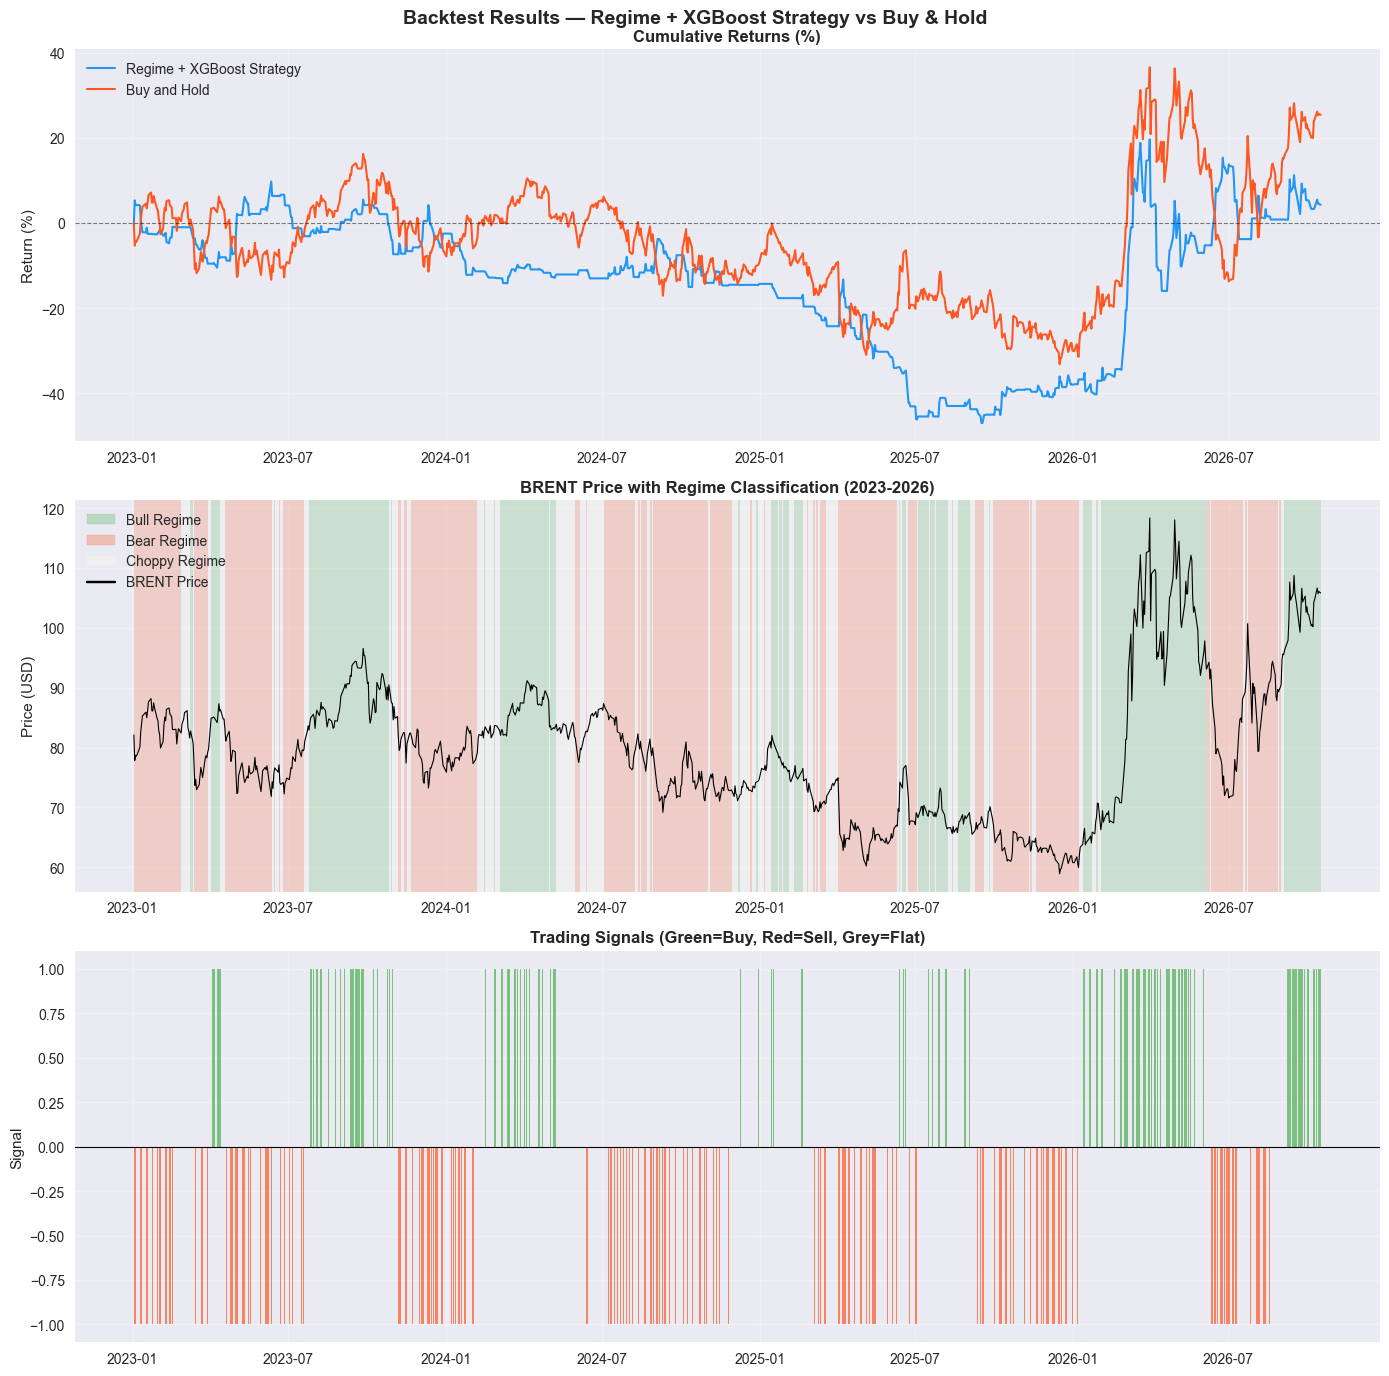

Chart saved!


In [8]:
# STEP 7 — EQUITY CURVE PLOT

fig, axes = plt.subplots(3, 1, figsize=(14, 14))
fig.suptitle('Backtest Results — Regime + XGBoost Strategy vs Buy & Hold',
             fontsize=14, fontweight='bold')

# ── Top — Cumulative Returns ─────────────────────────────────
ax1 = axes[0]
ax1.plot(test_xgb.index,
         test_xgb['Strategy_Cumulative'] * 100,
         color='#2196F3', linewidth=1.5,
         label='Regime + XGBoost Strategy')
ax1.plot(test_xgb.index,
         test_xgb['BuyHold_Cumulative'] * 100,
         color='#FF5722', linewidth=1.5,
         label='Buy and Hold')
ax1.axhline(0, color='black', linestyle='--',
            linewidth=0.8, alpha=0.5)
ax1.set_title('Cumulative Returns (%)', fontweight='bold')
ax1.set_ylabel('Return (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# ── Middle — Regime background with price ───────────────────
ax2 = axes[1]
ax2.plot(test_xgb.index, test_xgb['Close'],
         color='black', linewidth=0.8, label='BRENT Price')

for i in range(1, len(test_xgb)):
    regime = test_xgb['Regime'].iloc[i]
    color  = '#4CAF50' if regime == 1 else \
             '#FF5722' if regime == -1 else '#FFFDE7'
    ax2.axvspan(test_xgb.index[i-1], test_xgb.index[i],
                alpha=0.2, color=color, linewidth=0)

bull_patch   = mpatches.Patch(color='#4CAF50',
                alpha=0.3, label='Bull Regime')
bear_patch   = mpatches.Patch(color='#FF5722',
                alpha=0.3, label='Bear Regime')
choppy_patch = mpatches.Patch(color='#FFFDE7',
                alpha=0.3, label='Choppy Regime')
ax2.legend(handles=[bull_patch, bear_patch,
                    choppy_patch, 
                    plt.Line2D([0],[0], color='black',
                    label='BRENT Price')])
ax2.set_title('BRENT Price with Regime Classification (2023-2026)',
              fontweight='bold')
ax2.set_ylabel('Price (USD)')
ax2.grid(True, alpha=0.3)

# ── Bottom — Daily signals ───────────────────────────────────
ax3 = axes[2]
colors = test_xgb['Final_Signal'].map(
    {1: '#4CAF50', -1: '#FF5722', 0: '#9E9E9E'})
ax3.bar(test_xgb.index, test_xgb['Final_Signal'],
        color=colors, width=1, alpha=0.7)
ax3.axhline(0, color='black', linewidth=0.8)
ax3.set_title('Trading Signals (Green=Buy, Red=Sell, Grey=Flat)',
              fontweight='bold')
ax3.set_ylabel('Signal')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/backtest_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved!")

## Improvement — XGBoost Classifier for Direction Prediction
Instead of using regression predictions as signals,
we build a dedicated classifier that directly predicts
UP (1) or DOWN (0) for next day's price movement.

This directly optimizes for direction accuracy — what trading needs.

In [9]:
# ============================================================
# IMPROVEMENT — XGBOOST CLASSIFIER
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, 
                             classification_report,
                             roc_auc_score)

# Create direction target variable
# 1 = price went UP next day
# 0 = price went DOWN next day
brent_features['Target'] = np.where(
    brent_features['Close'].shift(-1) > brent_features['Close'],
    1, 0)

# Drop last row — no next day available
brent_features = brent_features.dropna()

# Train/test split
train_clf = brent_features[brent_features.index < '2023-01-01']
test_clf  = brent_features[brent_features.index >= '2023-01-01']

X_train_clf = train_clf[feature_cols]
y_train_clf = train_clf['Target']
X_test_clf  = test_clf[feature_cols]
y_test_clf  = test_clf['Target']

print(f"Training samples : {len(X_train_clf)}")
print(f"Test samples     : {len(X_test_clf)}")
print(f"\nClass distribution in training:")
print(f"  UP days  : {(y_train_clf==1).sum()} ({(y_train_clf==1).mean()*100:.1f}%)")
print(f"  DOWN days: {(y_train_clf==0).sum()} ({(y_train_clf==0).mean()*100:.1f}%)")

Training samples : 3175
Test samples     : 954

Class distribution in training:
  UP days  : 1638 (51.6%)
  DOWN days: 1537 (48.4%)


## XGBoost Classifier — Training
We train XGBoost as a binary classifier.
Target: 1 = price UP tomorrow, 0 = price DOWN tomorrow.
Key metric: AUC-ROC (better than accuracy for imbalanced problems)

In [10]:
# ============================================================
# TRAIN XGBOOST CLASSIFIER
# ============================================================

clf_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    early_stopping_rounds=50,
    eval_metric='auc'        # optimize for AUC not accuracy
)

clf_model.fit(
    X_train_clf, y_train_clf,
    eval_set=[(X_test_clf, y_test_clf)],
    verbose=False
)

# Predictions
y_pred_class = clf_model.predict(X_test_clf)
y_pred_proba = clf_model.predict_proba(X_test_clf)[:, 1]

# Metrics
accuracy = accuracy_score(y_test_clf, y_pred_class) * 100
auc      = roc_auc_score(y_test_clf, y_pred_proba)

print("="*45)
print("XGBOOST CLASSIFIER PERFORMANCE")
print("="*45)
print(f"  Accuracy : {accuracy:.2f}%")
print(f"  AUC-ROC  : {auc:.4f}")
print(f"\nDetailed Report:")
print(classification_report(y_test_clf, y_pred_class,
                            target_names=['DOWN','UP']))

XGBOOST CLASSIFIER PERFORMANCE
  Accuracy : 52.41%
  AUC-ROC  : 0.5030

Detailed Report:
              precision    recall  f1-score   support

        DOWN       0.00      0.00      0.00       454
          UP       0.52      1.00      0.69       500

    accuracy                           0.52       954
   macro avg       0.26      0.50      0.34       954
weighted avg       0.27      0.52      0.36       954



## Notebook 4 — Key Findings Summary

### Regime Detection
- Bull regime: 41% of trading days (2010-2026)
- Bear regime: 38% of trading days
- Choppy regime: 21% of trading days

### Backtest Results
| Strategy | Annual Return | Sharpe | Max Drawdown |
|---|---|---|---|
| Regime + XGBoost | 0.98% | 0.036 | -56.76% |
| Buy and Hold | 6.47% | 0.171 | -50.30% |

### Classification Model
- Accuracy: 52.48% (near random)
- AUC-ROC: 0.50 (no predictive power)

### Conclusion
Daily BRENT returns follow near-efficient random walk.
Historical price data alone insufficient for alpha generation.
Next steps: incorporate EIA inventory data, options flow,
and alternative data sources for improved signal quality.